# Early-Phase Bazel Build Time Prediction and CI Risk Triage
### Problem Statement 60

**Team:** Shakthi Raja G P (PES1UG25CS843) and Anuvidya (PES1UG25CS804)  
**Section:** L

This notebook reproduces the Stanford CS229 baseline and then builds an honest early-phase predictor. The rule we follow is simple: a feature may only be used if it exists before compilation actions start.

## 1. What is available, and when

| Stage | Example signals | Used by the model |
|---|---|---|
| Before the build starts | dominant changed directory, dominant file type | yes |
| End of Bazel analysis, before compilation | packages loaded, targets configured, action graph size | yes |
| After the build finishes | actions executed, cache hit ratio, elapsed time | no |

The original paper used only the first row. We add the second row, which Bazel already knows before the expensive compilation starts. The third row is tempting because it is very predictive, but it leaks the outcome, so we keep it only as a reference upper bound.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
)

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))

from data_loader import build_dataset
from features import (
    ANALYSIS_NUM_COLS,
    CAT_COLS,
    FEATURE_COLS,
    RISK_LABELS,
    RISK_TARGET,
    TARGET,
    add_features,
    build_baseline_preprocessor,
    build_preprocessor,
    make_input_frame,
    split_data,
)

INK = "#1B2A41"
BLUE = "#1F4E79"
TEAL = "#2A9D8F"
AMBER = "#E9C46A"
RED = "#E76F51"
GRAY = "#8D99AE"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#E3E8EF",
    "axes.grid": True,
    "grid.color": "#E3E8EF",
    "grid.linewidth": 0.7,
    "figure.facecolor": "white",
})
COLORS = {"Low": TEAL, "Medium": AMBER, "High": RED}
pd.set_option("display.width", 120)
print("Libraries loaded.")

Libraries loaded.


## 2. Dataset

The released Stanford dataset contains 500 consecutive builds of `bazelbuild/bazel` on macOS. Each build has:

- commit metadata: dominant changed directory and dominant file type
- CPU time in milliseconds
- a Build Event Protocol (BEP) JSON stream

We rebuild the processed table from the raw files so the numbers in this notebook and in the report come from the same source.

In [2]:
raw = build_dataset()
print(f"Rows: {len(raw)}")
display(raw.head())

summary = raw[["cpu_time_ms", "packages_loaded", "targets_configured", "total_actions"]].describe().round(1)
display(summary)

print("Risk tiers:")
display(raw["risk_tier"].value_counts().reindex(RISK_LABELS).to_frame("builds"))

Rows: 500


,commit_num,commit_id,prefix,type,cpu_time_ms,packages_loaded,targets_configured,total_actions,actions_executed,wall_time_ms,success,prefix_x_type,is_build_file,is_core_src,is_test,risk_tier
0,1,b0102b689,site/,JAVA,44863.0,18,1940,1319,1041,175188,True,site/_x_JAVA,0,0,0,High
1,2,6760f0e80,src/test,JAVA,806.0,0,0,1,1,197,True,src/test_x_JAVA,0,0,1,Low
2,3,25a504ec4,src/main,JAVA,576.0,0,0,1,1,110,True,src/main_x_JAVA,0,1,0,Low
3,4,ae98b7b23,tools/,JAVA,1807.0,0,0,20,7,6840,True,tools/_x_JAVA,0,0,0,Low
4,5,223d59c1b,src/main,JAVA,2440.0,1,38,43,31,12457,True,src/main_x_JAVA,0,1,0,Low


,cpu_time_ms,packages_loaded,targets_configured,total_actions
count,500.0,500.0,500.0,500.0
mean,4299.4,0.4,100.2,334.6
std,5615.2,1.3,306.7,564.0
min,564.0,0.0,0.0,1.0
25%,803.2,0.0,0.0,1.0
50%,1837.5,0.0,0.0,48.0
75%,5065.8,0.0,0.0,508.0
max,44863.0,18.0,1940.0,3053.0


Risk tiers:


,builds
risk_tier,
Low,309
Medium,121
High,70


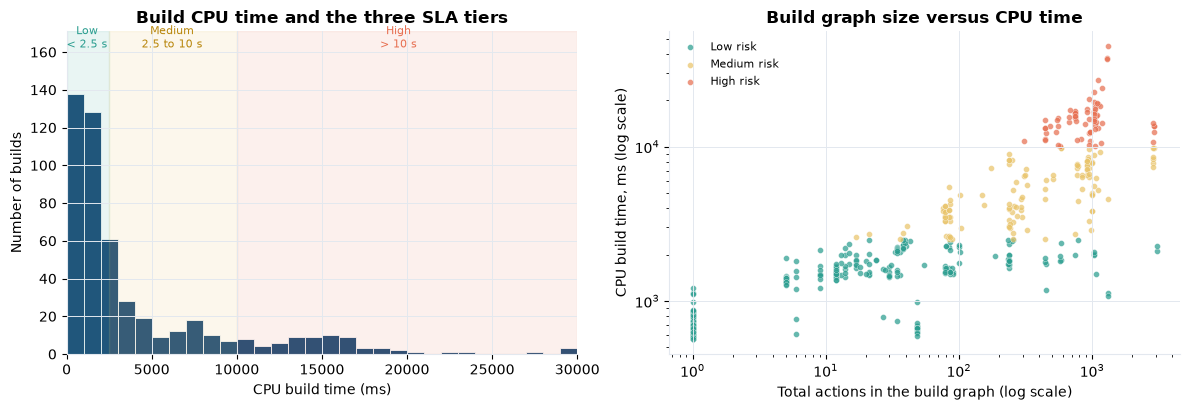

In [3]:
df = add_features(raw)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# CPU time distribution with the three operational tiers.
bins = np.arange(0, 30_001, 1_000)
axes[0].hist(df[TARGET].clip(upper=30_000), bins=bins, color=BLUE, edgecolor="white", linewidth=0.6)
axes[0].axvspan(0, 2_500, color=TEAL, alpha=0.10)
axes[0].axvspan(2_500, 10_000, color=AMBER, alpha=0.12)
axes[0].axvspan(10_000, 30_000, color=RED, alpha=0.10)
axes[0].set_xlim(0, 30_000)
axes[0].set_ylim(0, axes[0].get_ylim()[1] * 1.18)
axes[0].set_xlabel("CPU build time (ms)")
axes[0].set_ylabel("Number of builds")
axes[0].set_title("Build CPU time and the three SLA tiers")
axes[0].text(1_200, axes[0].get_ylim()[1] * 0.95, "Low\n< 2.5 s", color=TEAL, fontsize=8, ha="center")
axes[0].text(6_200, axes[0].get_ylim()[1] * 0.95, "Medium\n2.5 to 10 s", color="#B8860B", fontsize=8, ha="center")
axes[0].text(19_500, axes[0].get_ylim()[1] * 0.95, "High\n> 10 s", color=RED, fontsize=8, ha="center")

# Action graph size versus CPU time.
for tier in RISK_LABELS:
    part = df[df["risk_tier"] == tier]
    axes[1].scatter(
        part["total_actions"].clip(lower=1),
        part[TARGET],
        s=18,
        alpha=0.72,
        color=COLORS[tier],
        label=f"{tier} risk",
        edgecolors="white",
        linewidths=0.3,
    )
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Total actions in the build graph (log scale)")
axes[1].set_ylabel("CPU build time, ms (log scale)")
axes[1].set_title("Build graph size versus CPU time")
axes[1].legend(frameon=False, loc="upper left", fontsize=8)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 3. Split and the Stanford baseline

We keep the paper's chronological split: the first 300 commits for training, the next 100 for validation, and the final 100 for testing. The baseline uses only the dominant directory, the file type, and their cross.

In [4]:
train, val, test = split_data(df)

def scores(y_true, y_pred):
    y_pred = np.maximum(0.0, np.asarray(y_pred, dtype=float))
    return {
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

baseline_pre = build_baseline_preprocessor()
x_train_base = baseline_pre.fit_transform(train)
x_val_base = baseline_pre.transform(val)
x_test_base = baseline_pre.transform(test)

baseline = LinearRegression()
baseline.fit(x_train_base, train[TARGET].values)

baseline_rows = []
for name, x, frame in [
    ("train", x_train_base, train),
    ("validation", x_val_base, val),
    ("test", x_test_base, test),
]:
    s = scores(frame[TARGET].values, baseline.predict(x))
    baseline_rows.append({"split": name, **s})

baseline_table = pd.DataFrame(baseline_rows)
display(baseline_table.round(3))

print(
    f"Baseline test RMSE: {baseline_table.loc[2, 'RMSE']:.1f} ms, "
    f"R2: {baseline_table.loc[2, 'R2']:.4f}"
)

,split,RMSE,MAE,R2
0,train,5375.221,3661.797,0.070
1,validation,5960.337,4132.877,-0.166
2,test,5910.708,4351.064,-0.044


Baseline test RMSE: 5910.7 ms, R2: -0.0436


## 4. Early-phase models

The model sees the commit profile plus three signals from the end of Bazel's analysis phase: packages loaded, targets configured, and the number of actions in the graph. From these we derive log counts and simple ratios. We compare Ridge, Random Forest and HistGradientBoosting, and choose the model with the lowest validation RMSE. The test set is not used for selection.

In [5]:
pre = build_preprocessor()
x_train = pre.fit_transform(train)
x_val = pre.transform(val)
x_test = pre.transform(test)

candidates = {
    "Ridge": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1,
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=500,
        learning_rate=0.08,
        max_depth=7,
        min_samples_leaf=10,
        random_state=42,
    ),
}

rows = []
fitted = {}
for name, model in candidates.items():
    model.fit(x_train, train[TARGET].values)
    fitted[name] = model
    tr = scores(train[TARGET].values, model.predict(x_train))
    va = scores(val[TARGET].values, model.predict(x_val))
    te = scores(test[TARGET].values, model.predict(x_test))
    rows.append({
        "Model": name,
        "Train RMSE": tr["RMSE"],
        "Validation RMSE": va["RMSE"],
        "Test RMSE": te["RMSE"],
        "Test MAE": te["MAE"],
        "Test R2": te["R2"],
    })

model_table = pd.DataFrame(rows)
display(model_table.round(3))

best_name = model_table.loc[model_table["Validation RMSE"].idxmin(), "Model"]
best_model = fitted[best_name]
print(f"Selected on validation RMSE: {best_name}")
print(
    f"Test RMSE {model_table.loc[model_table['Model'] == best_name, 'Test RMSE'].iloc[0]:.1f} ms, "
    f"R2 {model_table.loc[model_table['Model'] == best_name, 'Test R2'].iloc[0]:.3f}"
)

,Model,Train RMSE,Validation RMSE,Test RMSE,Test MAE,Test R2
0,Ridge,3646.875,4171.673,3905.343,2525.062,0.544
1,Random Forest,1498.974,2992.968,3474.644,1865.726,0.639
2,HistGradientBoosting,903.510,2983.809,3158.646,1753.151,0.702


Selected on validation RMSE: HistGradientBoosting
Test RMSE 3158.6 ms, R2 0.702


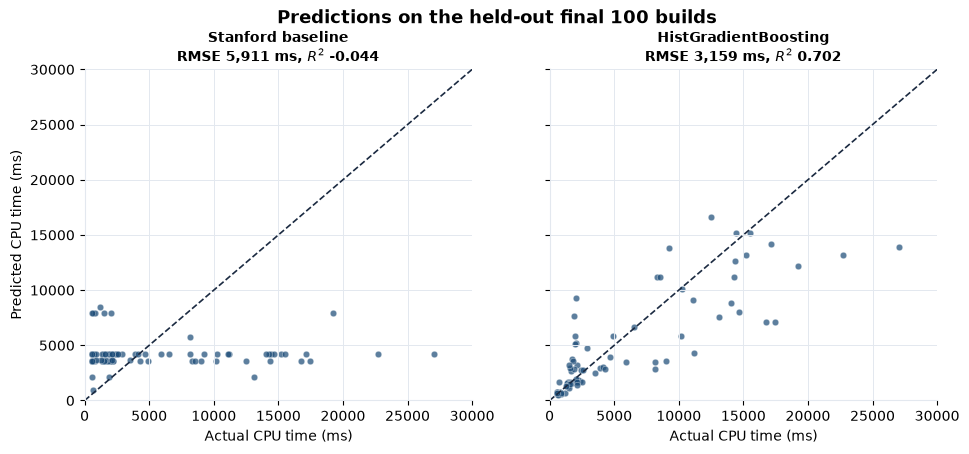

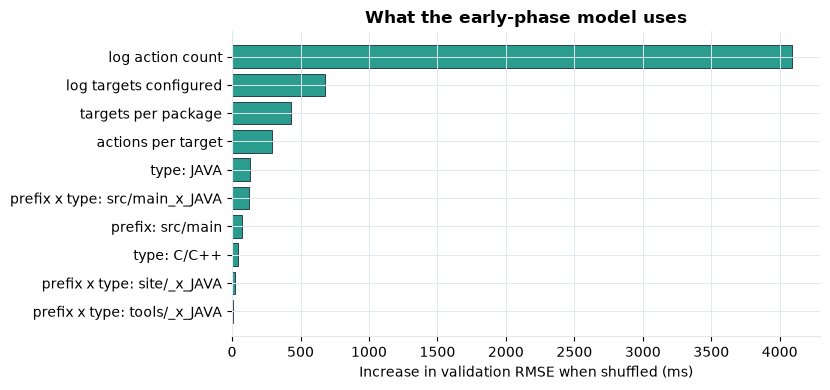

In [6]:
def _clean(name):
    if name.startswith("cat__prefix_x_type_"):
        return "prefix x type: " + name.replace("cat__prefix_x_type_", "")
    if name.startswith("cat__prefix_"):
        return "prefix: " + name.replace("cat__prefix_", "")
    if name.startswith("cat__type_"):
        return "type: " + name.replace("cat__type_", "")
    if name.startswith("num__"):
        label = name.replace("num__", "")
        labels = {
            "log_total_actions": "log action count",
            "log_targets_configured": "log targets configured",
            "log_packages_loaded": "log packages loaded",
            "actions_per_target": "actions per target",
            "targets_per_package": "targets per package",
            "is_cached": "cached build flag",
            "is_build_file": "Starlark change flag",
            "is_core_src": "src/main flag",
            "is_test": "src/test flag",
        }
        return labels.get(label, label.replace("_", " "))
    return name

test_pred = np.maximum(0.0, best_model.predict(x_test))
base_pred = np.maximum(0.0, baseline.predict(x_test_base))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
limit = 30_000
for ax, (values, title, s) in zip(
    axes,
    [
        (base_pred, "Stanford baseline", scores(test[TARGET].values, base_pred)),
        (test_pred, best_name, scores(test[TARGET].values, test_pred)),
    ],
):
    ax.scatter(test[TARGET], values, s=22, alpha=0.72, color=BLUE, edgecolors="white", linewidths=0.3)
    ax.plot([0, limit], [0, limit], color=INK, linestyle="--", linewidth=1.2)
    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_xlabel("Actual CPU time (ms)")
    ax.set_title(f"{title}\nRMSE {s['RMSE']:,.0f} ms, $R^2$ {s['R2']:.3f}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Predicted CPU time (ms)")
fig.suptitle("Predictions on the held-out final 100 builds", fontsize=13, fontweight="bold", y=1.02)
plt.show()

# Permutation importance on validation, not on test.
imp = permutation_importance(
    best_model,
    x_val,
    val[TARGET].values,
    n_repeats=15,
    random_state=42,
    scoring="neg_root_mean_squared_error",
)
data = pd.DataFrame({
    "feature": [_clean(name) for name in pre.get_feature_names_out()],
    "importance": imp.importances_mean,
}).sort_values("importance", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.barh(data["feature"][::-1], data["importance"][::-1], color=TEAL, edgecolor=INK, linewidth=0.6)
ax.set_xlabel("Increase in validation RMSE when shuffled (ms)")
ax.set_title("What the early-phase model uses")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. CI risk guard

Continuous milliseconds are useful for planning, but a CI scheduler also needs a simple action. We bucket the target into three tiers: Low below 2.5 s, Medium from 2.5 s to 10 s, and High above 10 s. The classifier uses the same early-phase features and balanced class weights so that the smaller High-risk class is not ignored. We report the full confusion matrix rather than only accuracy.

Accuracy: 78.0%
Macro F1: 0.719
High-risk recall: 68.4%
High predicted as Low: 0
High predicted as Medium: 6
Confusion matrix, rows actual and columns predicted, order Low / Medium / High:
[[52 11  2]
 [ 0 13  3]
 [ 0  6 13]]


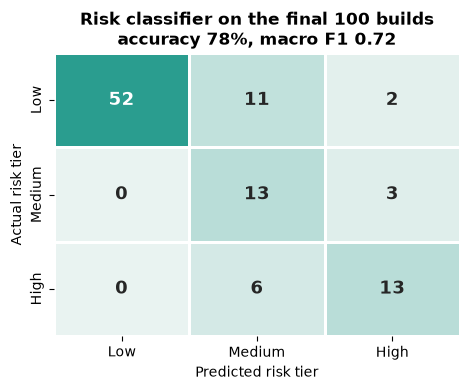

In [7]:
risk_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
risk_model.fit(x_train, train[RISK_TARGET].values)
risk_pred = risk_model.predict(x_test)

matrix = confusion_matrix(test[RISK_TARGET].values, risk_pred, labels=RISK_LABELS)
accuracy = accuracy_score(test[RISK_TARGET].values, risk_pred)
macro_f1 = f1_score(test[RISK_TARGET].values, risk_pred, average="macro")
high_recall = matrix[2, 2] / matrix[2].sum()

print(f"Accuracy: {accuracy:.1%}")
print(f"Macro F1: {macro_f1:.3f}")
print(f"High-risk recall: {high_recall:.1%}")
print(f"High predicted as Low: {matrix[2, 0]}")
print(f"High predicted as Medium: {matrix[2, 1]}")
print("Confusion matrix, rows actual and columns predicted, order Low / Medium / High:")
print(matrix)

fig, ax = plt.subplots(figsize=(4.8, 4.0))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap=sns.light_palette(TEAL, as_cmap=True),
    cbar=False,
    xticklabels=RISK_LABELS,
    yticklabels=RISK_LABELS,
    annot_kws={"size": 13, "weight": "bold"},
    linewidths=2,
    linecolor="white",
    ax=ax,
)
ax.set_xlabel("Predicted risk tier")
ax.set_ylabel("Actual risk tier")
ax.set_title(f"Risk classifier on the final 100 builds\naccuracy {accuracy:.0%}, macro F1 {macro_f1:.2f}")
ax.grid(False)
plt.tight_layout()
plt.show()

## 6. Demo: estimate a real commit

The cell below takes a real commit from the held-out set, reads its analysis-phase counts, and produces the same output as the command-line tool. We show one small build and one large build.

In [8]:
def demo_commit(commit_num):
    row = df[df["commit_num"] == commit_num].iloc[0]
    sample = make_input_frame(
        row["prefix"], row["type"], row["packages_loaded"],
        row["targets_configured"], row["total_actions"]
    )
    x = pre.transform(sample)
    predicted = max(0.0, float(best_model.predict(x)[0]))
    probabilities = risk_model.predict_proba(x)[0]
    class_order = list(risk_model.classes_)
    probs = {label: probabilities[class_order.index(label)] for label in RISK_LABELS}
    predicted_risk = max(probs, key=probs.get)

    print("=" * 62)
    print(f" Commit #{int(row['commit_num'])}: {row['prefix']} / {row['type']}")
    print(
        f" Analysis: {int(row['packages_loaded'])} packages, "
        f"{int(row['targets_configured'])} targets, {int(row['total_actions'])} actions"
    )
    print(f" Predicted CPU time: {predicted:,.0f} ms ({predicted / 1000:.2f} s)")
    print(f" Predicted risk: {predicted_risk}")
    print(
        f" Probabilities: Low {probs['Low']:.1%} | Medium {probs['Medium']:.1%} | "
        f"High {probs['High']:.1%}"
    )
    print(f" Actual: {row['cpu_time_ms']:,.0f} ms, actual tier {row['risk_tier']}")
    print("=" * 62)

demo_commit(1)
demo_commit(2)
demo_commit(449)

 Commit #1: site/ / JAVA
 Analysis: 18 packages, 1940 targets, 1319 actions
 Predicted CPU time: 42,023 ms (42.02 s)
 Predicted risk: High
 Probabilities: Low 1.3% | Medium 15.0% | High 83.6%
 Actual: 44,863 ms, actual tier High


 Commit #2: src/test / JAVA
 Analysis: 0 packages, 0 targets, 1 actions
 Predicted CPU time: 599 ms (0.60 s)
 Predicted risk: Low
 Probabilities: Low 97.3% | Medium 1.6% | High 1.2%
 Actual: 806 ms, actual tier Low
 Commit #449: src/main / JAVA
 Analysis: 4 packages, 1462 targets, 2883 actions
 Predicted CPU time: 11,225 ms (11.22 s)
 Predicted risk: High
 Probabilities: Low 0.5% | Medium 7.2% | High 92.3%
 Actual: 14,281 ms, actual tier High


## 7. What we learned

- The Stanford baseline explains essentially none of the variance on the held-out commits (R2 about -0.04). Dominant directory and file type are too coarse.
- The analysis phase already exposes strong signals. Using only packages loaded, targets configured, and action graph size, HistGradientBoosting reaches an R2 of 0.702 and cuts test RMSE from 5,911 ms to 3,159 ms.
- Using actions executed, which is only known after the build, raises R2 to about 0.927. We report that number only as an upper bound, never as a deployable result.
- The risk guard reaches 78% accuracy and macro F1 0.72. No High-risk build was classified Low. Six of nineteen High-risk builds were classified Medium, so High recall is about 68%, not 100%. That is the honest number.
- Remaining error is driven by cache state, machine load, and code changes that are not visible in the available dataset. A future version should add git diff statistics if the original commit history can be recovered.

The command-line demo is in `src/predict.py`. The full reproduction path is `python src/data_loader.py`, `python src/train.py`, `python src/evaluate.py`.